In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 

In [2]:
df=pd.read_csv("C:/Users/kajah/Downloads/defective product detection (1).csv")


In [3]:
df.head()

,ProductID,ProductionLine,Temperature,Pressure,AssemblyTime,Sensor1Reading,Sensor2Reading,Sensor3Reading,OperatorExperience,Defective
0,3011.353284,LineB,82.796721,93.188329,217.256896,1.105416,0.435081,0.581961,0.999832,1
1,4758.062422,LineA,97.762225,109.112115,144.435309,0.821272,0.517351,0.711407,4.315856,1
2,6315.999773,LineA,72.943564,54.219583,190.762139,1.184304,0.828455,0.955717,3.487675,0
3,3897.637627,LineC,89.837109,107.521954,257.605056,NaN,0.663670,1.036943,0.594878,1
4,7976.834849,LineB,78.789582,77.431668,169.523668,0.821755,0.836506,0.987433,6.836934,0


In [4]:
df.shape

(10000, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ProductID           10000 non-null  float64
 1   ProductionLine      10000 non-null  str    
 2   Temperature         9485 non-null   float64
 3   Pressure            9474 non-null   float64
 4   AssemblyTime        10000 non-null  float64
 5   Sensor1Reading      9531 non-null   float64
 6   Sensor2Reading      10000 non-null  float64
 7   Sensor3Reading      10000 non-null  float64
 8   OperatorExperience  9516 non-null   float64
 9   Defective           10000 non-null  int64  
dtypes: float64(8), int64(1), str(1)
memory usage: 830.2 KB


In [6]:
df.nunique()

ProductID             10000
ProductionLine            3
Temperature            9485
Pressure               9474
AssemblyTime          10000
Sensor1Reading         9531
Sensor2Reading        10000
Sensor3Reading        10000
OperatorExperience     9516
Defective                 2
dtype: int64

In [7]:
df.isnull().sum()

ProductID               0
ProductionLine          0
Temperature           515
Pressure              526
AssemblyTime            0
Sensor1Reading        469
Sensor2Reading          0
Sensor3Reading          0
OperatorExperience    484
Defective               0
dtype: int64

In [8]:
num_cols = ["Temperature", "Pressure", "Sensor1Reading", "OperatorExperience"]
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [9]:
df.isnull().sum()

ProductID             0
ProductionLine        0
Temperature           0
Pressure              0
AssemblyTime          0
Sensor1Reading        0
Sensor2Reading        0
Sensor3Reading        0
OperatorExperience    0
Defective             0
dtype: int64

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- 1. Scan all numeric columns ----------
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)

num_cols = df.select_dtypes(include='number').columns

summary = pd.DataFrame({
    'outliers': df[num_cols].apply(iqr_outliers).sum(),
    'percent': (df[num_cols].apply(iqr_outliers).mean() * 100).round(2),
    'skew': df[num_cols].skew().round(2)
}).sort_values('outliers', ascending=False)
print(summary)

                    outliers  percent  skew
Sensor1Reading           739     7.39 -0.96
ProductID                  0     0.00  0.03
Temperature                0     0.00  0.03
Pressure                   0     0.00 -0.00
AssemblyTime               0     0.00  0.02
Sensor2Reading             0     0.00 -0.26
Sensor3Reading             0     0.00  0.06
OperatorExperience         0     0.00 -0.01
Defective                  0     0.00  0.18


<Axes: xlabel='Sensor1Reading'>

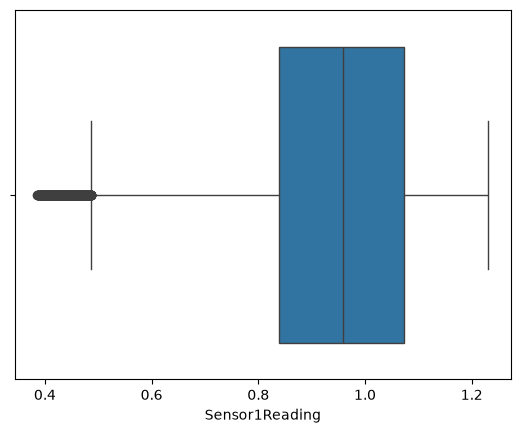

In [11]:
sns.boxplot(x='Sensor1Reading',data=df)

In [12]:
import pandas as pd
from scipy.stats import f_oneway

# Target column
target = 'Defective'

# Select continuous numerical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Remove the target column
numerical_columns = numerical_columns.drop(target, errors='ignore')

# Store results
anova_results = []

for col in numerical_columns:

    group_0 = df[df[target] == 0][col].dropna()
    group_1 = df[df[target] == 1][col].dropna()

    # Perform ANOVA test
    f_stat, p_value = f_oneway(group_0, group_1)

    anova_results.append({
        'Feature': col,
        'F_Statistic': f_stat,
        'P_Value': p_value,
        'Relationship': 'Significant' if p_value < 0.05 else 'Not Significant'
    })

# Display results
anova_df = pd.DataFrame(anova_results)
display(anova_df.sort_values(by='P_Value'))

,Feature,F_Statistic,P_Value,Relationship
1,Temperature,1921.298954,0.000000e+00,Significant
4,Sensor1Reading,2104.547894,0.000000e+00,Significant
5,Sensor2Reading,1727.919039,0.000000e+00,Significant
7,OperatorExperience,696.487672,1.947434e-148,Significant
2,Pressure,282.315695,1.684929e-62,Significant
6,Sensor3Reading,145.870765,2.363622e-33,Significant
3,AssemblyTime,2.918744,8.758704e-02,Not Significant
0,ProductID,0.062399,8.027495e-01,Not Significant


In [13]:
import pandas as pd
from scipy.stats import chi2_contingency

target = 'Defective'

# Select categorical columns
categorical_columns = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns

# Remove the target column
categorical_columns = categorical_columns.drop(
    target, errors='ignore'
)

chi_results = []

for col in categorical_columns:

    # Create a contingency table
    contingency_table = pd.crosstab(df[col], df[target])

    # Perform Chi-Square test
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_results.append({
        'Feature': col,
        'Chi2_Statistic': chi2,
        'P_Value': p_value,
        'Relationship': 'Significant'
        if p_value < 0.05 else 'Not Significant'
    })

# Display results
chi_df = pd.DataFrame(chi_results)

display(chi_df.sort_values(by='P_Value'))

C:\Users\kajah\AppData\Local\Temp\ipykernel_8388\4172671111.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,Feature,Chi2_Statistic,P_Value,Relationship
0,ProductionLine,3.46887,0.1765,Not Significant


In [14]:
df.drop(columns=["ProductID","ProductionLine","AssemblyTime"],inplace=True)

C:\Users\kajah\AppData\Local\Temp\ipykernel_8388\3242206285.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["ProductID","ProductionLine","AssemblyTime"],inplace=True)


In [15]:
df.head()

,Temperature,Pressure,Sensor1Reading,Sensor2Reading,Sensor3Reading,OperatorExperience,Defective
0,82.796721,93.188329,1.105416,0.435081,0.581961,0.999832,1
1,97.762225,109.112115,0.821272,0.517351,0.711407,4.315856,1
2,72.943564,54.219583,1.184304,0.828455,0.955717,3.487675,0
3,89.837109,107.521954,0.959139,0.663670,1.036943,0.594878,1
4,78.789582,77.431668,0.821755,0.836506,0.987433,6.836934,0


In [16]:
x=df.iloc[:,0:6]
x

,Temperature,Pressure,Sensor1Reading,Sensor2Reading,Sensor3Reading,OperatorExperience
0,82.796721,93.188329,1.105416,0.435081,0.581961,0.999832
1,97.762225,109.112115,0.821272,0.517351,0.711407,4.315856
2,72.943564,54.219583,1.184304,0.828455,0.955717,3.487675
3,89.837109,107.521954,0.959139,0.663670,1.036943,0.594878
4,78.789582,77.431668,0.821755,0.836506,0.987433,6.836934
...,...,...,...,...,...,...
9995,85.935636,80.893890,1.031425,1.181627,1.119016,1.609739
9996,70.829880,50.413979,0.959139,1.210240,0.748722,6.050626
9997,67.796020,67.803674,0.540040,0.727018,1.346599,0.500042
9998,71.047685,104.635048,0.602319,0.480117,1.401416,1.681758


In [17]:
y=df.iloc[:,6]
y

0       1
1       1
2       0
3       1
4       0
       ..
9995    1
9996    0
9997    1
9998    1
9999    0
Name: Defective, Length: 10000, dtype: int64

In [18]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y, test_size=0.2,random_state=42)

In [19]:
x_test

,Temperature,Pressure,Sensor1Reading,Sensor2Reading,Sensor3Reading,OperatorExperience
6252,72.477180,90.520852,0.959139,1.005748,0.720866,5.436961
4684,85.405143,98.378504,0.572381,1.154588,1.001293,5.020166
1731,87.689526,105.809024,1.065414,0.652923,1.185437,5.020166
4742,79.899195,42.969351,0.491148,0.462099,1.059519,3.815750
4521,79.899195,58.904612,0.935598,0.585306,1.010483,1.926055
...,...,...,...,...,...,...
6412,89.700805,112.316721,0.874457,1.250741,1.093294,4.044072
8285,88.069256,41.688966,1.043245,1.092032,0.921292,2.150144
7853,73.428076,51.386673,1.200489,0.848331,0.675574,3.408340
1095,78.097483,56.058014,1.065774,1.300724,0.934774,2.990904


In [20]:
y_train.value_counts()

Defective
0    4361
1    3639
Name: count, dtype: int64

In [21]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(sampling_strategy='minority')
x_sm, y_sm = smote.fit_resample(x_train, y_train)
y_sm.value_counts()

Defective
0    4361
1    4361
Name: count, dtype: int64

In [22]:
from sklearn.tree import DecisionTreeClassifier
model=DecisionTreeClassifier(criterion= 'entropy', max_depth= None, min_samples_leaf= 1, min_samples_split= 2)

In [23]:
model.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sa

In [24]:
x_pred=model.predict(x_train)

In [25]:
from sklearn.metrics import accuracy_score
a_score=accuracy_score(x_pred,y_train)
a_score

1.0

In [26]:
y_pred=model.predict(x_test)

In [27]:
from sklearn.metrics import accuracy_score
a_score=accuracy_score(y_pred,y_test)
a_score

0.9015

In [28]:
from sklearn.metrics import classification_report
report=classification_report(y_pred,y_test)
print(report)

              precision    recall  f1-score   support

           0       0.91      0.91      0.91      1082
           1       0.89      0.90      0.89       918

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

param_grid = {'criterion': ['gini', 'entropy'],'max_depth': [None, 3, 5, 10],'min_samples_split': [2, 5, 10],'min_samples_leaf': [1, 2, 4]
}

dt=DecisionTreeClassifier()
# GridSearchCV
grid_search = GridSearchCV(estimator=dt,param_grid=param_grid,cv=5,scoring='accuracy',)

# Train
grid_search.fit(x_train, y_train)

# Best parameters
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best CV Accuracy: 0.880625


In [30]:
import joblib

joblib.dump(model, "model.pkl")

['model.pkl']